In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
from datasets import load_dataset

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
# from tensorflow.keras.layers import Embedding, MultiHeadAttention, Dense, Input, Dropout, LayerNormalization, Flatten
# from tensorflow.keras.models import Model, load_model

# from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import MultiLabelBinarizer

import os
# plot libraries
from plotnine import ggplot, aes, geom_line


2024-05-01 09:53:10.982896: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-05-01 09:53:14.651048: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-05-01 09:53:14.651137: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-05-01 09:53:15.197710: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-01 09:53:16.254062: I tensorflow/core/platform/cpu_feature_guar

In [2]:
# custom imports
from encoder import *

In [3]:
emotion_data = load_dataset("go_emotions", "simplified")
emotion_data = emotion_data.filter(lambda x: len(x["labels"]) == 1)
emotion_data

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 36308
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 4548
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 4590
    })
})

In [8]:
all_emotions = [ "admiration", "amusement", "anger", "annoyance", "approval", "caring", "confusion", "curiosity", "desire", 
                "disappointment", "disapproval", "disgust", "embarrassment", "excitement", "fear", "gratitude", "grief", "joy", 
                "love", "nervousness", "optimism", "pride", "realization", "relief", "remorse", "sadness", "surprise", "neutral"]

num_label = len(all_emotions)

# transform labels
def one_hot_encode(labels, num_classes):
    mlb = MultiLabelBinarizer()
    mlb.fit([list(range(num_classes))])
    return mlb.transform(labels)

In [10]:
# hyperparameters
num_layers = 2
d_model = 256
num_heads = 8
dff = 512
num_words = 10000
input_vocab_size = num_words + 1
max_length = 120

In [11]:
# create tokenizer
tokenizer = Tokenizer(num_words=num_words, oov_token="<OOV>")
tokenizer.fit_on_texts(emotion_data["train"]["text"])

# tokenize and pad sequences
X_train = tokenize_and_pad(emotion_data["train"]["text"], tokenizer, max_length)
X_val = tokenize_and_pad(emotion_data["validation"]["text"], tokenizer, max_length)
X_test = tokenize_and_pad(emotion_data["test"]["text"], tokenizer, max_length)

In [12]:
Y_train = one_hot_encode(emotion_data["train"]["labels"], num_label)
Y_val = one_hot_encode(emotion_data["validation"]["labels"], num_label)
Y_test = one_hot_encode(emotion_data["test"]["labels"], num_label)

In [19]:
def train_model(
    X_train, y_train, X_val, y_val, 
    num_layers, d_model, num_heads, dff, input_vocab_size, max_length, learning_rate, epochs,
    log_file='training_log.csv'
):
    model = EncoderCategoryTransformer(num_layers, d_model, num_heads, dff, input_vocab_size, max_length, num_label)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
    
    callback = tf.keras.callbacks.CSVLogger(log_file)
    try:
        if X_val is None or y_val is None:
            history = model.fit(X_train, y_train, batch_size=32, epochs=epochs, callbacks=[callback], validation_split=0.2)
        else:
            history = model.fit(X_train, y_train, batch_size=32, epochs=epochs, validation_data=(X_val, y_val), callbacks=[callback])
    except Exception as e:
        print(e)
        history = None
    
    return model, history

In [17]:
# train model on 100 epochs, learning rate 0.001
model, history = train_model(X_train, Y_train, X_val, Y_val, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.001, 100, 'training_log_emotion_0.001.csv')

# evaluate model
result = model.evaluate(X_test, Y_test)

2024-05-01 10:00:25.959779: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-05-01 10:00:30.282081: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-05-01 10:00:30.282431: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

Epoch 1/100


2024-05-01 10:00:35.343407: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-05-01 10:00:38.627255: I external/local_xla/xla/service/service.cc:168] XLA service 0x7fe50cc51fd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-05-01 10:00:38.627298: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070, Compute Capability 8.9
2024-05-01 10:00:38.792573: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-05-01 10:00:39.127500: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
I0000 00:00:1714572039.302680    6712 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1135/1135 [==============================] - 39s 25ms/step - loss: 2.3943 - accuracy: 0.4180 - val_loss: 2.2025 - val_accuracy: 0.4624
Epoch 2/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.2281 - accuracy: 0.4525 - val_loss: 2.1697 - val_accuracy: 0.4595
Epoch 3/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.1541 - accuracy: 0.4555 - val_loss: 2.1012 - val_accuracy: 0.4666
Epoch 4/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.0723 - accuracy: 0.4749 - val_loss: 2.0269 - val_accuracy: 0.4872
Epoch 5/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.0042 - accuracy: 0.4969 - val_loss: 1.9822 - val_accuracy: 0.5128
Epoch 6/100
1135/1135 [==============================] - 24s 22ms/step - loss: 1.9659 - accuracy: 0.5061 - val_loss: 1.9436 - val_accuracy: 0.5207
Epoch 7/100
1135/1135 [==============================] - 25s 22ms/step - loss: 1.9284 - accuracy: 0.5163 - val_loss: 1.9375 - val_

ResourceExhaustedError: training_log_emotion_0.001.csv; No space left on device

In [ ]:
# read training log
log = pd.read_csv('training_log_emotion_0.001.csv')

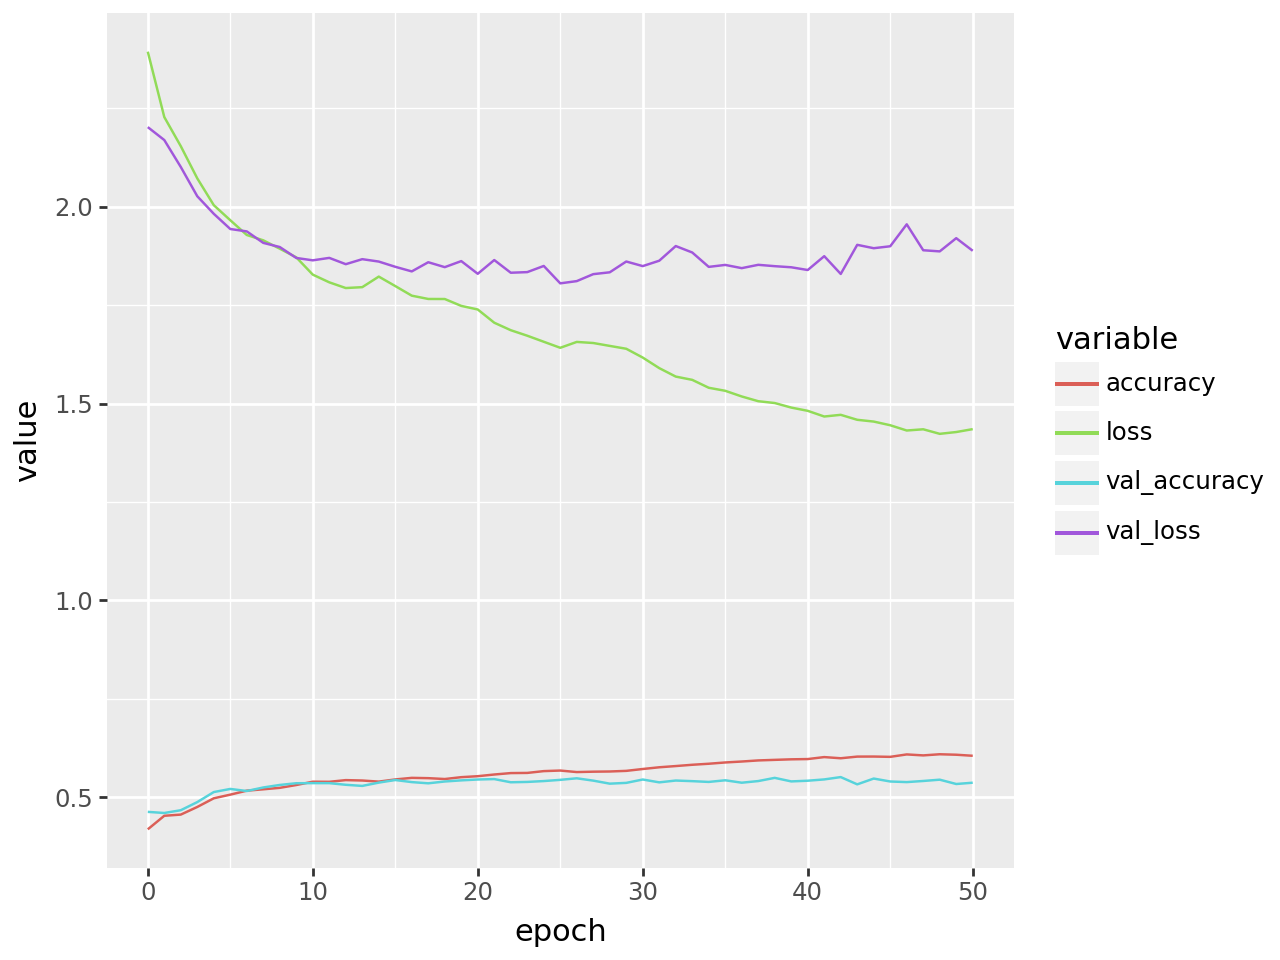

In [21]:
# epoch	accuracy	loss	val_accuracy	val_loss
log = log.melt(id_vars=['epoch'])

ggplot(log, aes(x='epoch', y='value', color='variable')) + geom_line()

In [22]:
# 0.01
model2, history2 = train_model(X_train, Y_train, X_val, Y_val, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 0.01, 100, 'training_log_emotion_0.01.csv')

Epoch 1/100
1135/1135 [==============================] - 31s 25ms/step - loss: 2.6261 - accuracy: 0.3528 - val_loss: 2.5909 - val_accuracy: 0.3500
Epoch 2/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.5759 - accuracy: 0.3531 - val_loss: 2.5236 - val_accuracy: 0.3500
Epoch 3/100
1135/1135 [==============================] - 25s 22ms/step - loss: 2.3926 - accuracy: 0.3864 - val_loss: 2.2961 - val_accuracy: 0.4134
Epoch 4/100
1135/1135 [==============================] - 26s 23ms/step - loss: 2.2900 - accuracy: 0.4122 - val_loss: 2.2384 - val_accuracy: 0.4112
Epoch 5/100
1135/1135 [==============================] - 26s 23ms/step - loss: 2.2539 - accuracy: 0.4178 - val_loss: 2.2028 - val_accuracy: 0.4250
Epoch 6/100
1135/1135 [==============================] - 26s 23ms/step - loss: 2.2838 - accuracy: 0.4115 - val_loss: 2.2324 - val_accuracy: 0.4191
Epoch 7/100
1135/1135 [==============================] - 26s 23ms/step - loss: 2.2423 - accuracy: 0.4183 - val_loss: 2

In [23]:
# evaluate model
result2 = model2.evaluate(X_test, Y_test)
print(f"Model 2: {result2}")

144/144 [==============================] - 1s 10ms/step - loss: 2.2710 - accuracy: 0.4832
Model 2: [2.2710065841674805, 0.48322439193725586]


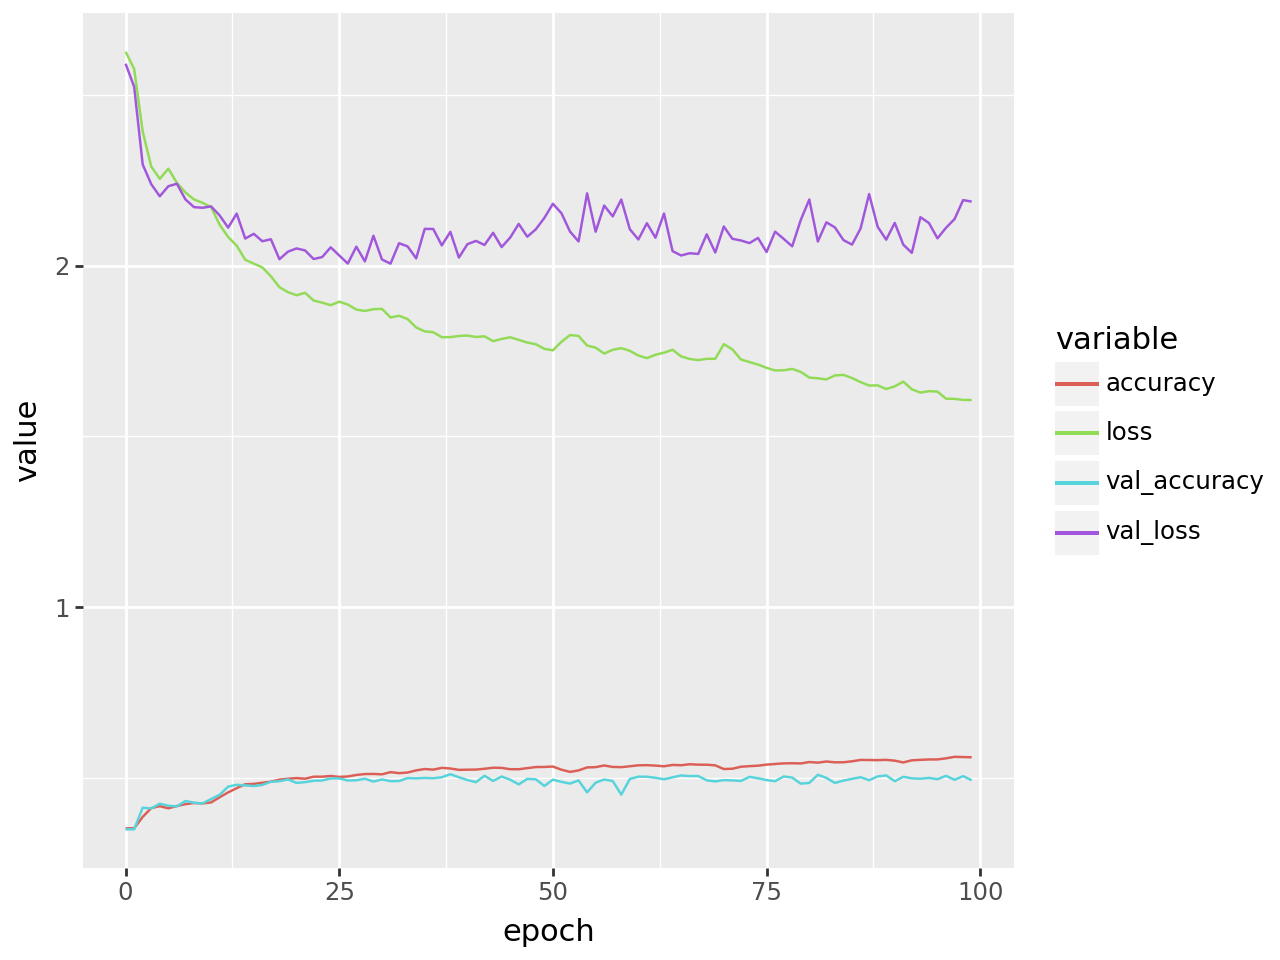

In [25]:
# read training log
log2 = pd.read_csv('training_log_emotion_0.01.csv')

log2 = log2.melt(id_vars=['epoch'])

ggplot(log2, aes(x='epoch', y='value', color='variable')) + geom_line()

In [27]:
# 1e-4
model3, history3 = train_model(X_train, Y_train, X_val, Y_val, num_layers, d_model, num_heads, dff, input_vocab_size, max_length, 1e-4, 1000, 'training_log_emotion_1e-4.csv')

Epoch 1/1000
1135/1135 [==============================] - 31s 25ms/step - loss: 2.0970 - accuracy: 0.4876 - val_loss: 1.7172 - val_accuracy: 0.5666
Epoch 2/1000
1135/1135 [==============================] - 26s 23ms/step - loss: 1.6404 - accuracy: 0.5692 - val_loss: 1.5805 - val_accuracy: 0.5831
Epoch 3/1000
1135/1135 [==============================] - 26s 23ms/step - loss: 1.4477 - accuracy: 0.5964 - val_loss: 1.5410 - val_accuracy: 0.5831
Epoch 4/1000
1135/1135 [==============================] - 25s 22ms/step - loss: 1.2781 - accuracy: 0.6296 - val_loss: 1.5993 - val_accuracy: 0.5677
Epoch 5/1000
1135/1135 [==============================] - 26s 23ms/step - loss: 1.1181 - accuracy: 0.6658 - val_loss: 1.6921 - val_accuracy: 0.5372
Epoch 6/1000
1135/1135 [==============================] - 25s 22ms/step - loss: 0.9780 - accuracy: 0.7049 - val_loss: 1.7665 - val_accuracy: 0.5627
Epoch 7/1000
1135/1135 [==============================] - 26s 23ms/step - loss: 0.8484 - accuracy: 0.7379 - val_

KeyboardInterrupt: 

In [28]:
# evaluate model
result3 = model3.evaluate(X_test, Y_test)

NameError: name 'model3' is not defined

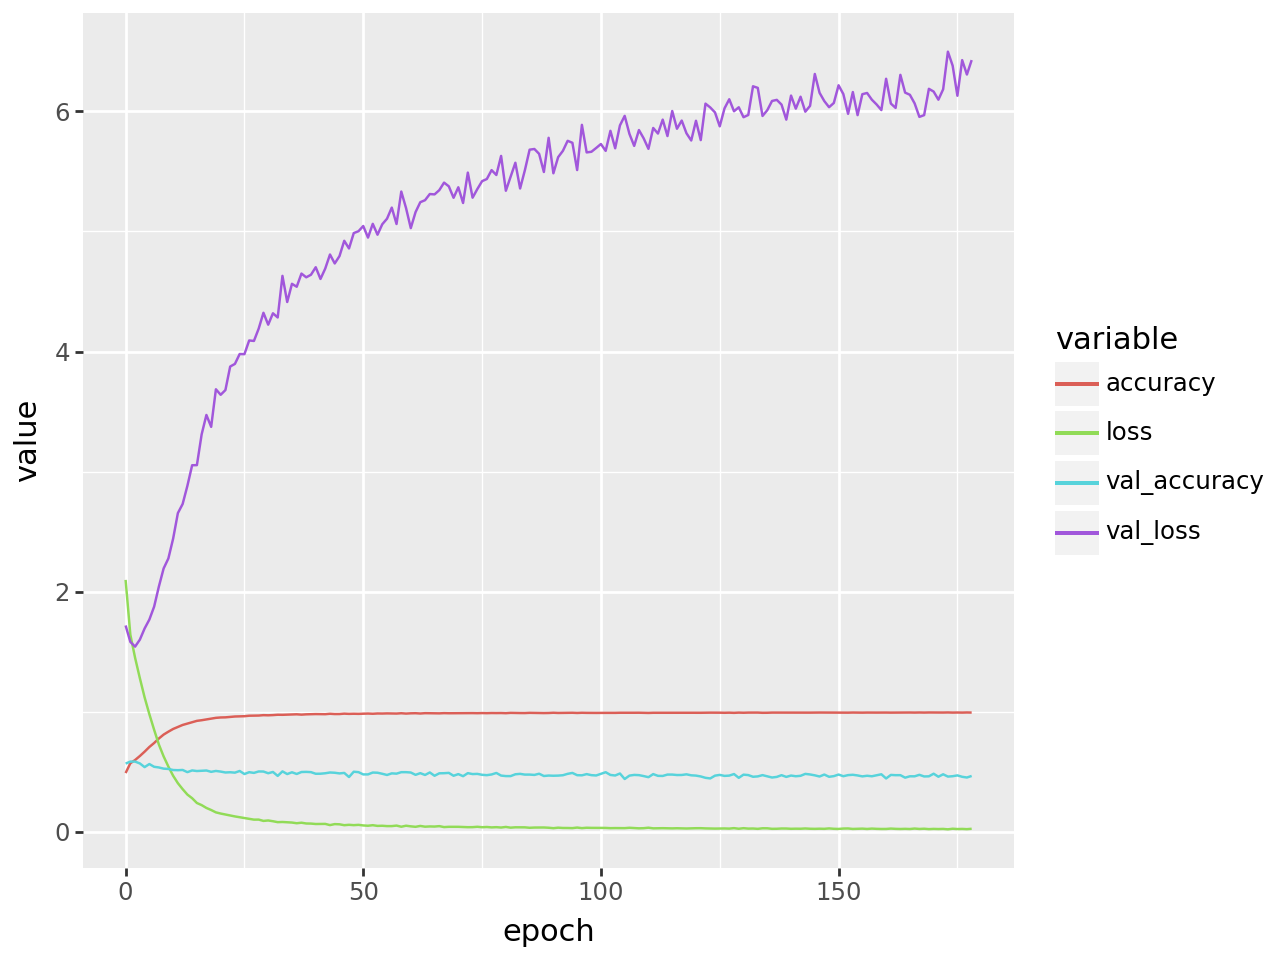

In [29]:
# read training log
log3 = pd.read_csv('training_log_emotion_1e-4.csv')

log3 = log3.melt(id_vars=['epoch'])

ggplot(log3, aes(x='epoch', y='value', color='variable')) + geom_line()